# FDM expansion for Diffusive Equations

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
import sympy as sp
import numpy as np
import re as regex
from sympy.tensor.indexed import Indexed
from IPython.display import display, Math, Latex
%run ~/Desktop/Bazarin-R.L.M.-AcademicDocumentation/docs/source/modules/eq_funcs.ipynb

us = sp.symbols('u_{x}^{t}')
omega = sp.symbols(r'\omega')
omg1=1-omega
cs = sp.symbols('c_s')

In [2]:
def make_shift_symbols(prefix=r'T_{\Delta_{x}}', order=5, var='c', start=0):
    names = [f'{prefix}^{{{var}_{{{i}}}}}' for i in range(start, start + order)]
    return sp.symbols(names)
Txc = make_shift_symbols(order=18, var='c')   # list of SymPy symbols
# Txc

In [3]:
def auto_collect(expr, ul):
    symbols = set(ul.values()) & expr.free_symbols
    symbols = sorted(symbols, key=sp.default_sort_key)
    return sp.collect(expr, symbols)

In [4]:
def wheigt_symbols(prefix=r'w', order=5, start=0):
    names = [f'{prefix}_{{{i}}}' for i in range(start, start + order)]
    return sp.symbols(names)
w = wheigt_symbols(order=18)   # list of SymPy symbols
# w[0]

 ## Two-Dimensional Cases: $D2Q9$ Lattices

In [5]:
import sympy as sp
#------------------Shift-Function-----------------------------------
def apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-2):
    if len(cx) != len(cy) or len(cx) > len(Txc):
        raise ValueError("Incompatible lattice velocity arrays")
    velocities = [(int(x), int(y)) for x, y in zip(cx, cy)]
    operators = Txc[:len(velocities)]
    if expr.has(*Txc[len(velocities):]):
        raise ValueError("Some shift operators have undefined velocities")
    result = []
    # Expand into individual additive terms
    for term in sp.Add.make_args(sp.expand(expr)):
        powers = term.as_powers_dict()
        counts = [powers.get(op, 0) for op in operators]# Number of occurrences of each shift operator
        operator_factor = sp.prod(op**n for op, n in zip(operators, counts) ) # Extract operator product
        other = term / operator_factor
        # ------Case 1: Shift operators acting on us-----------
        if powers.get(us, 0) == 1:

            dx = -sum(int(n) * vx for n, (vx, vy) in zip(counts, velocities))
            dy = -sum(int(n) * vy for n, (vx, vy) in zip(counts, velocities) )

            # Build dictionary key
            key = f"ut{time}"
            if dx:
                key += f"dx{dx:+d}"
            if dy:
                key += f"dy{dy:+d}"
            # Generate missing symbols automatically
            if key not in ul:
                te = f"t{time:+d}" if time else "t"
                xp = f"x{dx:+d}" if dx else "x"
                yp = f"y{dy:+d}" if dy else "y"
                ul[key] = sp.Symbol(fr"u^{{{te}}}_{{{xp},{yp}}}")
            result.append((other / us) * ul[key])
        # ---Case 2: Simplify shift operators not acting on us---
        else:
            reduced = [int(n) for n in counts]
            for i, (vx, vy) in enumerate(velocities):
                # Zero-velocity operator is identity
                if vx == 0 and vy == 0:
                    reduced[i] = 0
                    continue
                # Cancel opposite shifts
                for j in range(i + 1, len(velocities)):
                    if velocities[j] == (-vx, -vy):
                        m = min(reduced[i], reduced[j])
                        reduced[i] -= m
                        reduced[j] -= m
            remaining = sp.prod(op**n for op, n in zip(operators, reduced))
            result.append(other * remaining)
    return sp.Add(*result)

In [6]:
import sympy as sp
ul = {}
past_steps = [1, 2, 3, 4, 5, 6]
space_offsets = [1, 2, 3, 4, 5, 6]
# Time mapping
time_map = {"+1": "t+1","0": "t",**{f"-{k}": f"t-{k}" for k in past_steps},}
# Non-shifted symbols
for tk, te in time_map.items():
    ul[f"ut{tk}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y}}')
# Shifted symbols (skip future time "+1")
for tk, te in time_map.items():
    if tk == "+1":
        continue
    for ssign in ("+", "-"):
        for d in space_offsets:
            # Shift in x
            ul[f"ut{tk}dx{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x{ssign}{d},y}}')
            # Shift in y
            ul[f"ut{tk}dy{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y{ssign}{d}}}')
    # Simultaneous shifts in x and y
    for sx in ("+", "-"):
        for sy in ("+", "-"):
            for dx in space_offsets:
                for dy in space_offsets:
                    ul[f"ut{tk}dx{sx}{dx}dy{sy}{dy}"] = sp.Symbol(fr'u^{{{te}}}_{{x{sx}{dx},y{sy}{dy}}}')

In [7]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=5
cx=np.array([0, 1,-1, 0, 0])
cy=np.array([0, 0, 0, 1,-1])
wis=np.array([w[0],w[1],w[2],w[3],w[4]])
feq = us*wis

In [9]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum((-omg1)**(n-1) * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, q+1)
])

In [10]:
weights = {w[0]: sp.Rational(4, 9), **{w[i]: sp.Rational(1, 9) for i in range(1, 5)} }
# Automatically process all orders
mt = {}
for i in range(len(OrderT)):
    expr = sp.expand(OrderT[i])
    expr = apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-i)
    # mt[i] = auto_collect(expr.subs(weights), ul)
    expr_0=expr.subs({w[2]:w[1],w[3]:w[1],w[4]:w[1],w[0]:1-w[1]*4})
    mt[i] = auto_collect(expr_0, ul)
    print(f"Order {i}:")
    brokeq2(mt[i], terms_per_line=4)

Order 0:


<IPython.core.display.Math object>

Order 1:


<IPython.core.display.Math object>

Order 2:


<IPython.core.display.Math object>

Order 3:


<IPython.core.display.Math object>

Order 4:


<IPython.core.display.Math object>

In [14]:
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt[0]+mt[1]+mt[2]+mt[3]+mt[4]), terms_per_line=1, symbols=ul)))

<IPython.core.display.Math object>

In [15]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import re

def plot_fdm_stencil(mt, ul, cx, cy, figsize=(7, 7)):
    # ----------------1. Identify Cartesian positions from ul symbols----------------------------------
    pattern = re.compile(r"^ut(?:\+1|0|-\d+)"r"(?:dx([+-]\d+))?"r"(?:dy([+-]\d+))?$")
    # Reverse mapping: SymPy symbol -> dictionary key
    symbol_to_key = {v: k for k, v in ul.items()}
    points_by_order = {}
    for i, expr in mt.items():
        points = set()
        for symbol in expr.free_symbols:
            key = symbol_to_key.get(symbol)
            if key is None:
                continue
            match = pattern.fullmatch(key)
            if match is None:
                continue
            dx = int(match.group(1) or 0)
            dy = int(match.group(2) or 0)
            points.add((dx, dy))
        points_by_order[i] = points
    # --------------------Union of all Cartesian points------------------------------
    all_points = set().union(*points_by_order.values())
    if not all_points:
        raise ValueError("No shifted spatial symbols found.")
    # Original lattice velocities
    base_points = {(-int(x), -int(y)) for x, y in zip(cx, cy)}
    # Only count points actually present in mt
    black_points = all_points & base_points
    red_points = all_points - base_points
    # --------------------Print stencil information------------------------------
    # for i, points in sorted(points_by_order.items()):
    #     print(f"mt[{i}]: {len(points)} Cartesian points")

    # print(f"\nOriginal lattice points: {len(black_points)}")
    # print(f"Additional points:       {len(red_points)}")
    # print(f"Total stencil points:    {len(all_points)}")
    # ---------------------4. Plot-----------------------------
    fig, ax = plt.subplots(figsize=figsize)
    if black_points:
        x, y = zip(*sorted(black_points))
        ax.scatter(x, y, color="black", s=100, zorder=3)
    if red_points:
        x, y = zip(*sorted(red_points))
        ax.scatter(x, y, color="red", s=100, zorder=3)
    xs, ys = zip(*all_points)
    ax.set_xticks(np.arange(min(xs), max(xs) + 1))
    ax.set_yticks(np.arange(min(ys), max(ys) + 1))
    ax.set_xlim(min(xs) - 0.5, max(xs) + 0.5)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.set_aspect("equal")
    ax.grid(True, color="lightgray", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.set_xlabel(r"$\Delta x$")
    ax.set_ylabel(r"$\Delta y$")
    ax.set_title(f"{len(all_points)}-point stencil " f"({len(black_points)} + {len(red_points)})" )
    plt.tight_layout()
    plt.show()
    return all_points, points_by_order

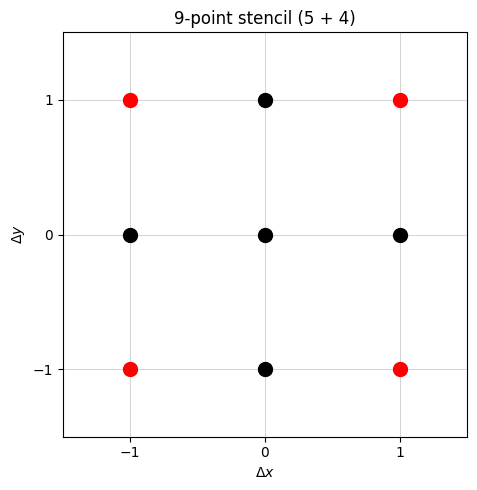

In [16]:
all_points, points_by_order = plot_fdm_stencil(mt, ul, cx, cy, figsize=(5, 5))

### Sympy Expansion

In [17]:
import sympy as sp
import re
from functools import lru_cache
from IPython.display import display, Math

# Spatial and temporal step sizes
dx, dy, dt = sp.symbols('Delta_x Delta_y Delta_t', positive=True, real=True)
nu = sp.symbols(r'\nu')

# Three independent continuous variables and the continuous field
x, y, t = sp.symbols('x y t', real=True)
usf = sp.Function('u')
Usf = usf(x, y, t)

# Optional shorthand for a symbol representing a partial derivative.
# Taylor expansions below use actual SymPy Derivative objects instead.
def d(name, nx=0, ny=0, nt=0):
    n = nx + ny + nt
    if n == 0:
        return sp.Symbol(name)
    num = rf'\partial^{{{n}}}{{{name}}}' if n > 1 else rf'\partial{{{name}}}'
    den = ''
    for variable, power in [('x', nx), ('y', ny), ('t', nt)]:
        if power:
            den += (rf'\partial{{{variable}^{{{power}}}}}' if power > 1
                    else rf'\partial{{{variable}}}')
    return sp.Symbol(rf'\frac{{{num}}}{{{den}}}')

# Representative symbolic derivative names if required later
dut = d('u', nt=1);dut2 = d('u', nt=2);dut3 = d('u', nt=3);dut4 = d('u', nt=4)
dux = d('u', nx=1);dux2 = d('u', nx=2);dux3 = d('u', nx=3);dux4 = d('u', nx=4)
duy = d('u', ny=1);duy2 = d('u', ny=2);duy3 = d('u', ny=3);duy4 = d('u', ny=4)
duxy = d('u', nx=1, ny=1);dux2y2 = d('u', nx=2, ny=2)
duxt = d('u', nx=1, nt=1);dux2t = d('u', nx=2, nt=1);dux2t2 = d('u', nx=2, nt=2)
duyt = d('u', ny=1, nt=1);duy2t = d('u', ny=2, nt=1);duy2t2 = d('u', ny=2, nt=2)

In [18]:
@lru_cache(maxsize=None)
def taylor_u(sx=0, sy=0, st=0, order=4, scaling='total'):
    """Taylor series for u(x+sx*dx, y+sy*dy, t+st*dt).

    scaling='total'     retains nx + ny + nt <= order
    scaling='diffusive' retains nx + ny + 2*nt <= order

    `order` is the truncation order in the selected scaling.
    """
    if scaling not in ('total', 'diffusive'):
        raise ValueError("scaling must be 'total' or 'diffusive'")
    if order < 0 or int(order) != order:
        raise ValueError('order must be a non-negative integer')

    wt = 1 if scaling == 'total' else 2
    sx, sy, st = int(sx), int(sy), int(st)
    terms = []

    for nx in range(order + 1):
        for ny in range(order - nx + 1):
            for nt in range((order - nx - ny) // wt + 1):
                # Terms with vanishing powers do not contribute.
                if (sx == 0 and nx > 0) or (sy == 0 and ny > 0) or (st == 0 and nt > 0):
                    continue

                coefficient = ((sx*dx)**nx * (sy*dy)**ny * (st*dt)**nt
                    / (sp.factorial(nx) * sp.factorial(ny) * sp.factorial(nt)))
                derivative = sp.diff(Usf, x, nx, y, ny, t, nt)
                terms.append(coefficient * derivative)

    return sp.Add(*terms)

# Examples: axis-aligned shift, diagonal shift and mixed space-time shift
# taylor_u(sx=-1, sy=0, st=0, order=4)
# taylor_u(sx=-1, sy=+1, st=0, order=4)
# taylor_u(sx=-1, sy=+1, st=-2, order=4, scaling='diffusive')


In [19]:
# -------Parse the dictionary keys generated by apply_velocity_shifts-----------
UL_PATTERN = re.compile(r'^ut(?P<st>\+1|0|-\d+)'r'(?:dx(?P<sx>[+-]\d+))?'r'(?:dy(?P<sy>[+-]\d+))?$')
def ul_offsets(key):
    """For instance: 'ut-2dx-1dy+2' -> (-1, +2, -2)."""
    match = UL_PATTERN.fullmatch(key)
    if match is None:
        raise ValueError(f'Unknown u-grid symbol key: {key}')
    return (int(match.group('sx') or 0),
            int(match.group('sy') or 0),
            int(match.group('st')))


def make_taylor_substitutions(mt, ul, order=4, scaling='total'):
    """Expand each distinct shifted u used by mt, including the LHS u(t+1).

    Returns
    -------
    taylor_subs : dict[SymPy Symbol, SymPy expression]
        Suitable for `expr.xreplace(taylor_subs)`.
    taylor_by_order : dict[int, dict[SymPy Symbol, SymPy expression]]
        Taylor series for precisely the u symbols occurring in each mt[i].
    """
    symbol_to_key = {symbol: key for key, symbol in ul.items()}

    taylor_by_order = {}
    for i, expr in sorted(mt.items()):
        found = set(expr.free_symbols).intersection(symbol_to_key)
        taylor_by_order[i] = {
            symbol: taylor_u(*ul_offsets(symbol_to_key[symbol]),
                             order=order, scaling=scaling)
            for symbol in sorted(found, key=sp.default_sort_key)
        }

    all_used = set().union(*(part.keys() for part in taylor_by_order.values()))
    all_used.add(ul['ut+1'])  # the FDM equation's left-hand side
    taylor_subs = {
        symbol: taylor_u(*ul_offsets(symbol_to_key[symbol]),
                         order=order, scaling=scaling)
        for symbol in sorted(all_used, key=sp.default_sort_key)
    }
    return taylor_subs, taylor_by_order


# ------------------------------------------------------------------------------
# 2. Generate every required Taylor polynomial for D2Q9 FDM stencil
# ------------------------------------------------------------------------------
TAYLOR_ORDER = 4
TAYLOR_SCALING = 'total'       # Choose 'diffusive' for dt ~ dx^2

taylor_subs, taylor_by_order = make_taylor_substitutions(
    mt, ul, order=TAYLOR_ORDER, scaling=TAYLOR_SCALING
)

for i, series in taylor_by_order.items():
    print(f'mt[{i}]: {len(series)} shifted u values expanded')
print(f'Total distinct shifted u values (including t+1): {len(taylor_subs)}')

# Display a few examples. Change DISPLAY_ALL to True to print every expansion.
DISPLAY_ALL = False
DISPLAY_EXAMPLES = ['ut+1', 'ut0', 'ut0dx-1', 'ut0dy+1', 'ut0dx-1dy+1', 'ut-1dx+1dy-1']
keys_to_show = ([key for key, sym in ul.items() if sym in taylor_subs]
                if DISPLAY_ALL else DISPLAY_EXAMPLES)
for key in keys_to_show:
    if key in ul and ul[key] in taylor_subs:
        display(Math(sp.latex(ul[key]) + ' = ' + sp.latex(taylor_subs[ul[key]])))


mt[0]: 5 shifted u values expanded
mt[1]: 9 shifted u values expanded
mt[2]: 9 shifted u values expanded
mt[3]: 5 shifted u values expanded
mt[4]: 1 shifted u values expanded
Total distinct shifted u values (including t+1): 30


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Checking symmetri of the solution

In [21]:
# Identify all u symbols present in the expression
mt_sum_c=sum(mt[i] for i in range(q))
u_symbols = sorted(set(ul.values()) & mt_sum_c.free_symbols, key=sp.default_sort_key)
# Extract coefficients
coefficients = {u: sp.factor(mt_sum_c.coeff(u)) for u in u_symbols}

# Display coefficients
# for u, coefficient in coefficients.items():
#     display(sp.Eq(u, coefficient, evaluate=False))

# Sum coefficients by setting all u terms to 1
coeff_sum = sp.factor(mt_sum_c.subs({u: 1 for u in u_symbols}))
display(coeff_sum)

1

In [22]:
# Sum all temporal orders
mt_sum = taylor_subs[ul['ut+1']]-sum(mt[i] for i in range(q))
# Replace all shifted u terms with their Taylor expansions
mt_sum_taylor_0 = mt_sum.xreplace(taylor_subs)
# Expand and collect the resulting expression
mt_sum_taylor = sp.expand(mt_sum_taylor_0)
# Display
brokeq2(mt_sum_taylor, terms_per_line=4)

<IPython.core.display.Math object>

In [23]:
# Automatically substitute all derivatives
derivative_subs = {}
for deriv in mt_sum_taylor.atoms(sp.Derivative):
    nx = sum(n for v, n in deriv.variable_count if v == x)
    ny = sum(n for v, n in deriv.variable_count if v == y)
    nt = sum(n for v, n in deriv.variable_count if v == t)
    derivative_subs[deriv] = d('u', nx=nx, ny=ny, nt=nt)
# Replace derivatives and the zeroth-order field
mt_sum_taylor_symbols = mt_sum_taylor.xreplace(derivative_subs).subs(Usf, d('u'))
# Collect by derivative symbols
derivative_symbols = sorted(set(derivative_subs.values()), key=sp.default_sort_key)
mt_sum_taylor_symbols = sp.collect(mt_sum_taylor_symbols,derivative_symbols)
brokeq2(mt_sum_taylor_symbols, terms_per_line=3)

<IPython.core.display.Math object>

In [26]:
pde_0=sp.collect(sp.expand(dut-mt_sum_taylor_symbols/(omega**4*dt)),{dux2*dx**2/dt,duy2*dy**2/dt,dut2*dt,dut3*dt**2,dut4*dt**3,
                                                                    dux3*dx**3,dux4*dx**4,duy3*dy**3,duy4*dy**4,dux2t*dx**2,duy2t*dy**2,
                                                                    dux2t2*dx**2*dt,duy2t2*dy**2*dt,dux2y2*dy**2*dx**2}).subs(dut3,0).subs(dut4,0).subs(dux2t2,0).subs(duy2t2,0)
nus = sp.symbols('\\nu')
nut=dx**2/dt*(-w[1]+2*w[1]/omega)
pde_1=pde_0.subs(dy,dx).subs({nut:nus})
# brokeq2(pde_0, terms_per_line=4)
brokeq2(pde_1, terms_per_line=1)

<IPython.core.display.Math object>

$$
\frac{\partial\phi}{\partial t} = \nu \left(\frac{\partial^{2}\phi}{\partial x^{2}} + \frac{\partial^{2}\phi}{\partial y^{2}} \right), \qquad \frac{\partial^{2}\phi}{\partial t^{2}} = \nu^{2} \left(\frac{\partial^{4}\phi}{\partial x^{4}} + 2\frac{\partial^{4}\phi}{\partial x^{2}\partial y^{2}} + \frac{\partial^{4}\phi}{\partial y^{4}} \right), \qquad \frac{\partial^{3}\phi}{\partial x^{2}\partial t} = \nu \left( \frac{\partial^{4}\phi}{\partial x^{4}} + \frac{\partial^{4}\phi}{\partial x^{2}\partial y^{2}} \right), \qquad \frac{\partial^{3}\phi}{\partial y^{2}\partial t} = \nu \left( \frac{\partial^{4}\phi}{\partial y^{4}} + \frac{\partial^{4}\phi}{\partial x^{2}\partial y^{2}} \right),
$$

In [27]:
pde_2 = sp.collect(sp.expand( pde_1.subs(dut2,nut*nut*(dux4 + 2*dux2y2 + duy4))
                          .subs(dux2t,nut*(dux4 + dux2y2))
                          .subs(duy2t,nut*(duy4 + dux2y2))
                            .subs(dut3,0).subs(dut4,0).subs(dux2t2,0).subs(duy2t2,0).subs(dy,dx) )
                   ,{dux4*dx**4/dt,duy4*dx**4/dt,dux2y2*dx**4/dt})
pde_2

\frac{\partial^{2}{u}}{\partial{x^{2}}}*\nu + \frac{\partial^{2}{u}}{\partial{y^{2}}}*\nu + Delta_x**4*\frac{\partial^{4}{u}}{\partial{x^{2}}\partial{y^{2}}}*(w_{1}**2 - 10*w_{1}**2/\omega + 24*w_{1}**2/\omega**2 - 16*w_{1}**2/\omega**3)/Delta_t + Delta_x**4*\frac{\partial^{4}{u}}{\partial{x^{4}}}*(w_{1}**2/2 - w_{1}/12 - 5*w_{1}**2/\omega + 7*w_{1}/(6*\omega) + 12*w_{1}**2/\omega**2 - 3*w_{1}/\omega**2 - 8*w_{1}**2/\omega**3 + 2*w_{1}/\omega**3)/Delta_t + Delta_x**4*\frac{\partial^{4}{u}}{\partial{y^{4}}}*(w_{1}**2/2 - w_{1}/12 - 5*w_{1}**2/\omega + 7*w_{1}/(6*\omega) + 12*w_{1}**2/\omega**2 - 3*w_{1}/\omega**2 - 8*w_{1}**2/\omega**3 + 2*w_{1}/\omega**3)/Delta_t

In [29]:
pde_3=sp.collect(sp.expand(sp.simplify(sp.expand(pde_2.subs(dx**2/dt,nus*(dx**2/dt)/nut ) ))),{dux4*dx**2*nus,duy4*dx**2*nus,dux2y2*dx**2*nus,dux2*nus,duy2*nus})
pde_3

Delta_x**2*\frac{\partial^{4}{u}}{\partial{x^{2}}\partial{y^{2}}}*\nu*(-12*\omega**3*w_{1}/(12*\omega**3 - 24*\omega**2) + 120*\omega**2*w_{1}/(12*\omega**3 - 24*\omega**2) - 288*\omega*w_{1}/(12*\omega**3 - 24*\omega**2) + 192*w_{1}/(12*\omega**3 - 24*\omega**2)) + Delta_x**2*\frac{\partial^{4}{u}}{\partial{x^{4}}}*\nu*(-6*\omega**3*w_{1}/(12*\omega**3 - 24*\omega**2) + \omega**3/(12*\omega**3 - 24*\omega**2) + 60*\omega**2*w_{1}/(12*\omega**3 - 24*\omega**2) - 14*\omega**2/(12*\omega**3 - 24*\omega**2) - 144*\omega*w_{1}/(12*\omega**3 - 24*\omega**2) + 36*\omega/(12*\omega**3 - 24*\omega**2) + 96*w_{1}/(12*\omega**3 - 24*\omega**2) - 24/(12*\omega**3 - 24*\omega**2)) + Delta_x**2*\frac{\partial^{4}{u}}{\partial{y^{4}}}*\nu*(-6*\omega**3*w_{1}/(12*\omega**3 - 24*\omega**2) + \omega**3/(12*\omega**3 - 24*\omega**2) + 60*\omega**2*w_{1}/(12*\omega**3 - 24*\omega**2) - 14*\omega**2/(12*\omega**3 - 24*\omega**2) - 144*\omega*w_{1}/(12*\omega**3 - 24*\omega**2) + 36*\omega/(12*\omega**3 - 

In [31]:
dux2coef=sp.collect(pde_3.coeff(dux2*nu),{12*omega**3-24*omega**2})
dux2coef

1

In [32]:
duy2coef=sp.collect(pde_3.coeff(duy2*nu),{12*omega**3-24*omega**2})
duy2coef

1

In [34]:
dux4coef=sp.factor(sp.collect(pde_3.coeff(dux4*nu*dx**2),{12*omega**3-24*omega**2}))
dux4coef

-(6*\omega**2*w_{1} - \omega**2 - 48*\omega*w_{1} + 12*\omega + 48*w_{1} - 12)/(12*\omega**2)

In [35]:
duy4coef=sp.factor(sp.collect(pde_3.coeff(duy4*nu*dx**2),{12*omega**3-24*omega**2}))
duy4coef

-(6*\omega**2*w_{1} - \omega**2 - 48*\omega*w_{1} + 12*\omega + 48*w_{1} - 12)/(12*\omega**2)

In [36]:
dux2y2coef=sp.factor(sp.collect(pde_3.coeff(dux2y2*nu*dx**2),{12*omega**3-24*omega**2}))
dux2y2coef

-w_{1}*(\omega**2 - 8*\omega + 8)/\omega**2

In [81]:
(omega**2-8*omega+8)*(w[1]+2*w[2]) - (omega**2-12*omega+12)/(w[1]+2*w[2])

(w_{1} + 2*w_{2})*(\omega**2 - 8*\omega + 8) - (\omega**2 - 12*\omega + 12)/(w_{1} + 2*w_{2})